### Cooperation networks over different conditions

In [20]:
import pandas as pd
import json
import seaborn as sns
import numpy as np

import networkx as nx

from pyvis.network import Network

import sys

sys.path.append("../functions/")
import networks

In [21]:
import os

In [22]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [23]:
with open("../data/Venturelli2018/generated/metid2metname.json") as json_file:
    metid2metname = json.load(json_file)

In [24]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = media_db[media_db.medium=="M9"].compound.values
compounds = list(compounds)
compounds.remove("glc__D")
m9_compounds = ["M_"+met+"__91__e__93__" for met in compounds]

In [25]:
results_all = {}

for filename in os.listdir("../output/Venturelli2018/results_steadiercom/"):
    
    if filename.endswith(".tsv"):
        name = filename.replace(".tsv","")

        results_all[name] = pd.read_csv(f"../output/Venturelli2018/results_steadiercom/{filename}",sep="\t")

In [26]:
results = pd.concat(results_all).reset_index(drop=True)

results["mass_rate*frequency"] = results["frequency"]*results["mass_rate"]
results = results[~results.compound.isin(m9_compounds)]

In [27]:
abundances_exp = pd.read_csv("../data/Venturelli2018/generated/communities_12_exp_abundance.tsv",sep="\t")
abundances_exp.columns = ["community","member","abundance"]

abundances_exp = abundances_exp.set_index(["community","member"])["abundance"]
abundances_exp = abundances_exp.unstack().T
abundances_exp

community,BH-,BO-,BT-,BU-,BV-,CA-,CH-,DP-,EL-,ER-,FP-,NONE,PC-
member,,,,,,,,,,,,,
Bacteroides_ovatus_ATCC_8483,0.1663,NaN,0.2268,0.3229,0.1354,0.1840,0.1840,0.2149,0.4241,0.1343,0.2537,0.1533,0.1927
Bacteroides_thetaiotaomicron_VPI_5482,0.1714,0.2878,NaN,0.2036,0.2148,0.1644,0.1644,0.1476,0.0933,0.1607,0.2162,0.1452,0.1611
Bacteroides_uniformis_ATCC_8492,0.4236,0.2648,0.4698,NaN,0.3968,0.4358,0.4358,0.2646,0.0962,0.3809,0.3736,0.3649,0.3514
Bacteroides_vulgatus_ATCC_8482,0.0454,0.1536,0.0309,0.0912,NaN,0.0342,0.0342,0.0870,0.0660,0.0415,0.0581,0.0140,0.0348
Blautia_hydrogenotrophica_DSM_10507,NaN,0.0089,0.0222,0.0118,0.0140,0.0091,0.0091,0.0197,0.0002,0.0109,0.0038,0.0100,0.0088
Clostridium_hiranonis_TO_931_DSM_13275,0.0100,0.0175,0.0127,0.0097,0.0118,0.0175,NaN,0.0126,0.0024,0.0106,0.0275,0.0212,0.0122
Collinsella_aerofaciens_ATCC_25986,0.0185,0.0250,0.0325,0.0287,0.0266,NaN,0.0002,0.0179,0.0186,0.0255,0.0297,0.0249,0.0199
Desulfovibrio_piger_ATCC_29098,0.0025,0.0020,0.0006,0.0010,0.0010,0.0007,0.0007,NaN,0.0007,0.0006,0.0013,0.0019,0.0011
Eggerthella_lenta_DSM_2243,0.0210,0.0259,0.0168,0.0239,0.0216,0.0112,0.0112,0.0149,NaN,0.0190,0.0185,0.0168,0.0154


### Out degree (By count)!

In [28]:
centrality_metrics_comm= {}

for comm in results.community.unique():
    results_comm = results[results.community==comm].copy()
    
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=True,freq_cutoff=0.2)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

In [29]:
centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()
centrality

,Bacteroides_ovatus_ATCC_8483,Bacteroides_thetaiotaomicron_VPI_5482,Bacteroides_uniformis_ATCC_8492,Bacteroides_vulgatus_ATCC_8482,Blautia_hydrogenotrophica_DSM_10507,Clostridium_hiranonis_TO_931_DSM_13275,Collinsella_aerofaciens_ATCC_25986,Desulfovibrio_piger_ATCC_29098,Eggerthella_lenta_DSM_2243,Eubacterium_rectale_ATCC_33656,Faecalibacterium_prausnitzii_A2_165,Prevotella_copri_CB7_DSM_18205
BH-,11.0,4.0,8.0,2.0,NaN,6.0,3.0,0.0,8.0,0.0,9.0,1.0
BO-,NaN,5.0,6.0,3.0,1.0,7.0,4.0,0.0,8.0,0.0,10.0,NaN
BT-,9.0,NaN,7.0,1.0,1.0,8.0,4.0,0.0,6.0,0.0,7.0,NaN
BU-,16.0,4.0,NaN,2.0,1.0,5.0,4.0,0.0,2.0,1.0,11.0,4.0
BV-,9.0,4.0,7.0,NaN,1.0,5.0,5.0,0.0,6.0,0.0,9.0,NaN
CA-,15.0,3.0,8.0,2.0,1.0,8.0,NaN,0.0,1.0,4.0,8.0,3.0
CH-,14.0,2.0,9.0,2.0,1.0,NaN,2.0,0.0,0.0,5.0,7.0,4.0
DP-,15.0,4.0,9.0,2.0,1.0,6.0,2.0,NaN,7.0,0.0,10.0,0.0
EL-,17.0,2.0,0.0,2.0,0.0,5.0,5.0,0.0,NaN,1.0,13.0,3.0
ER-,10.0,3.0,9.0,2.0,1.0,6.0,5.0,0.0,8.0,NaN,11.0,0.0


In [30]:
#sorter = centrality.max().sort_values().index
sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

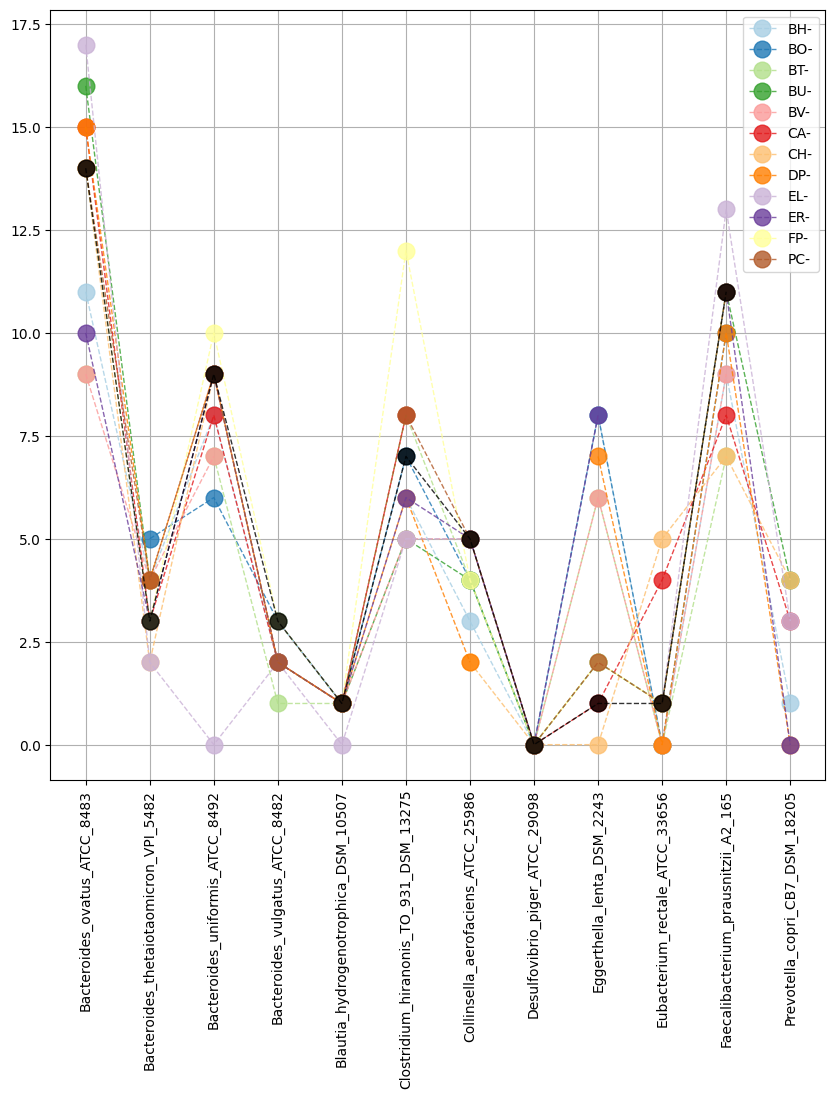

In [31]:

ax = centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired")
centrality_sorted.T["NONE"].plot(ax=ax,color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)

x = centrality_sorted.columns.values
ax.set_xticks(np.arange(len(x)))
labels = ax.set_xticklabels(x,rotation=90)

<Axes: ylabel='Frequency'>

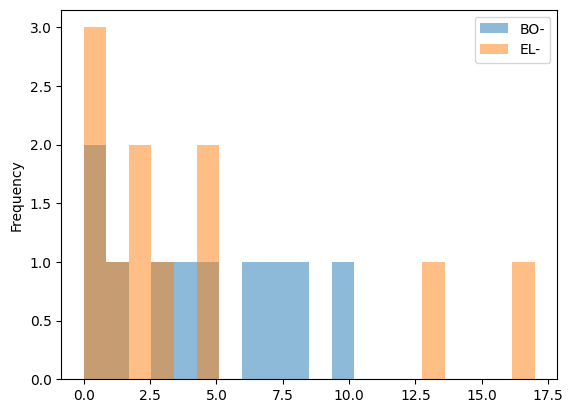

In [32]:
centrality_sorted.loc[["BO-","EL-"],:].T.plot(kind="hist",alpha=0.5,bins=20)

<Axes: ylabel='Frequency'>

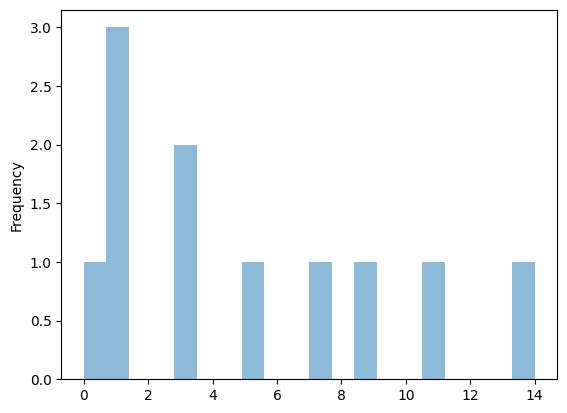

In [33]:
centrality_sorted.loc["NONE",:].T.plot(kind="hist",alpha=0.5,bins=20)

### In degree (By count)!

In [34]:
centrality_metrics_comm= {}

for comm in results.community.unique():
    results_comm = results[results.community==comm].copy()
    
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=True,freq_cutoff=0.2)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="in")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

In [35]:
centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()
centrality

,Bacteroides_ovatus_ATCC_8483,Bacteroides_thetaiotaomicron_VPI_5482,Bacteroides_uniformis_ATCC_8492,Bacteroides_vulgatus_ATCC_8482,Blautia_hydrogenotrophica_DSM_10507,Clostridium_hiranonis_TO_931_DSM_13275,Collinsella_aerofaciens_ATCC_25986,Desulfovibrio_piger_ATCC_29098,Eggerthella_lenta_DSM_2243,Eubacterium_rectale_ATCC_33656,Faecalibacterium_prausnitzii_A2_165,Prevotella_copri_CB7_DSM_18205
BH-,4.0,12.0,5.0,7.0,NaN,9.0,5.0,5.0,2.0,3.0,0.0,0.0
BO-,NaN,8.0,3.0,7.0,4.0,8.0,5.0,3.0,3.0,3.0,0.0,NaN
BT-,4.0,NaN,5.0,8.0,2.0,8.0,6.0,4.0,3.0,2.0,1.0,NaN
BU-,2.0,11.0,NaN,5.0,2.0,7.0,5.0,6.0,4.0,3.0,2.0,3.0
BV-,4.0,11.0,4.0,NaN,2.0,10.0,6.0,3.0,3.0,3.0,0.0,NaN
CA-,3.0,12.0,5.0,5.0,4.0,8.0,NaN,8.0,3.0,2.0,1.0,2.0
CH-,3.0,10.0,5.0,5.0,3.0,NaN,5.0,5.0,4.0,3.0,1.0,2.0
DP-,4.0,13.0,5.0,8.0,2.0,10.0,6.0,NaN,4.0,2.0,0.0,2.0
EL-,2.0,10.0,5.0,6.0,2.0,6.0,5.0,3.0,NaN,3.0,2.0,4.0
ER-,4.0,12.0,5.0,7.0,3.0,11.0,7.0,2.0,3.0,NaN,0.0,1.0


In [36]:
#sorter = centrality.max().sort_values().index
sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

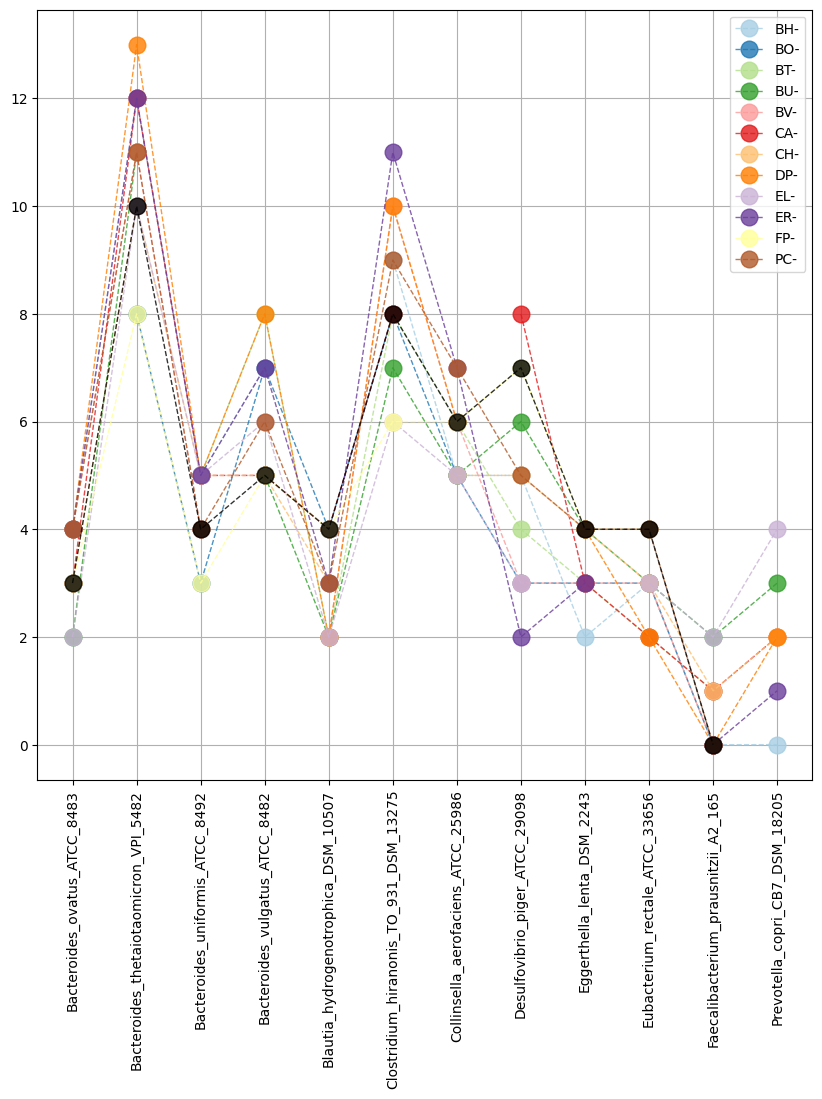

In [37]:

ax = centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired")
centrality_sorted.T["NONE"].plot(ax=ax,color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)

x = centrality_sorted.columns.values
ax.set_xticks(np.arange(len(x)))
labels = ax.set_xticklabels(x,rotation=90)

### Out degree (frequency)

In [45]:
centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.2)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


#sorter = centrality.max().sort_values().index
sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

ER-
DP-
PC-
EL-
BT-
BU-
NONE
BV-
CH-
BO-
BH-
FP-
CA-


In [46]:
import matplotlib.pyplot as plt

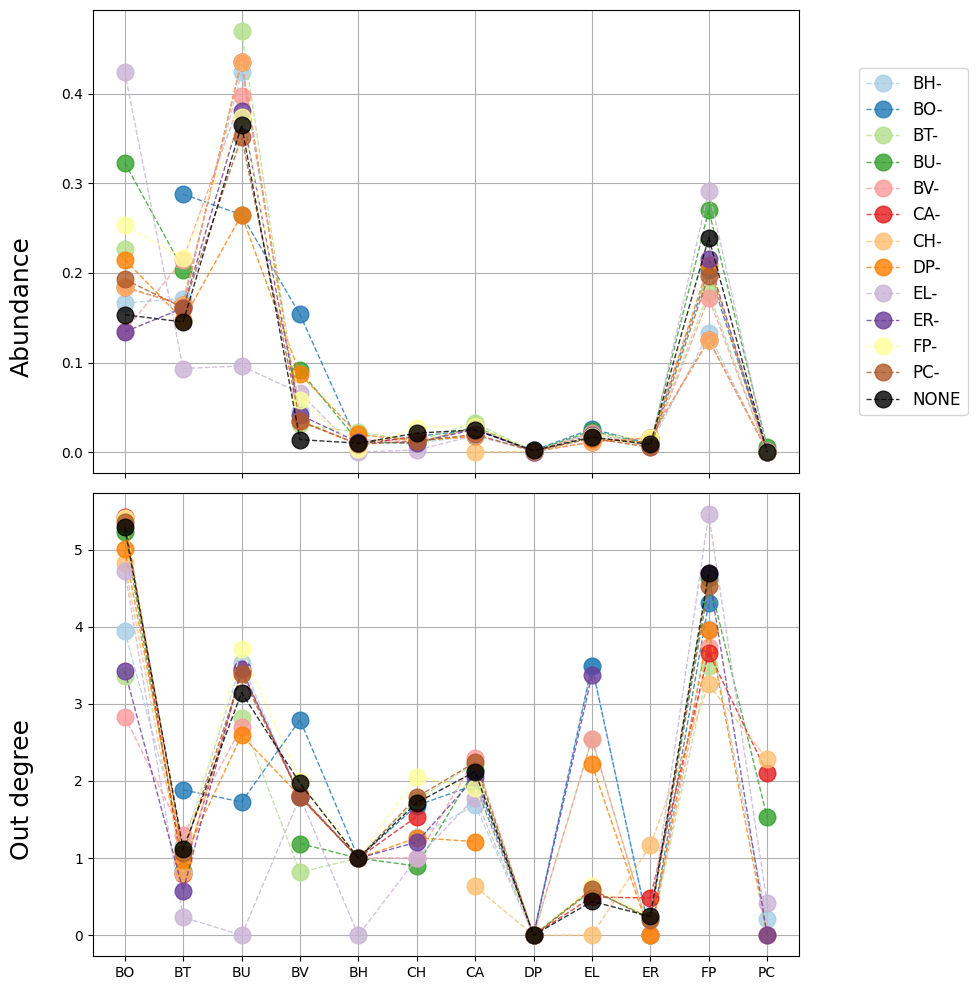

In [49]:
fig,ax = plt.subplots(2,figsize=(25,10))

abundances_exp_none = abundances_exp.drop("NONE",axis=1)

abundances_exp_none.plot(ax=ax[0],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
abundances_exp["NONE"].plot(ax=ax[0],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
labels = ax[0].set_xticklabels("",rotation=90)
title1 = ax[0].set_title("Abundance",x=-.1,y=0.2,fontsize=18,rotation=90)
ax[0].legend(loc='center right', bbox_to_anchor=(1.25, 0.5),fontsize=12)
ax[0].set_xlabel("")

centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(ax=ax[1],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
centrality_sorted.T["NONE"].plot(ax=ax[1],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
names = centrality_sorted.columns.values
x = [name.split("_")[0][0].upper()+name.split("_")[1][0].upper() for name in names]

ax[1].set_xticks(np.arange(len(x)))
labels = ax[1].set_xticklabels(x)
title2 = ax[1].set_title("Out degree",x=-.1,y=0.2,fontsize=18,rotation=90)
plt.tight_layout()
fig.savefig("figures/degree_comm_out.png")


### In degree (frequency)

In [50]:
centrality_metrics_comm= {}

for comm in results.community.unique():
    results_comm = results[results.community==comm].copy()
    
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="in")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()

sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

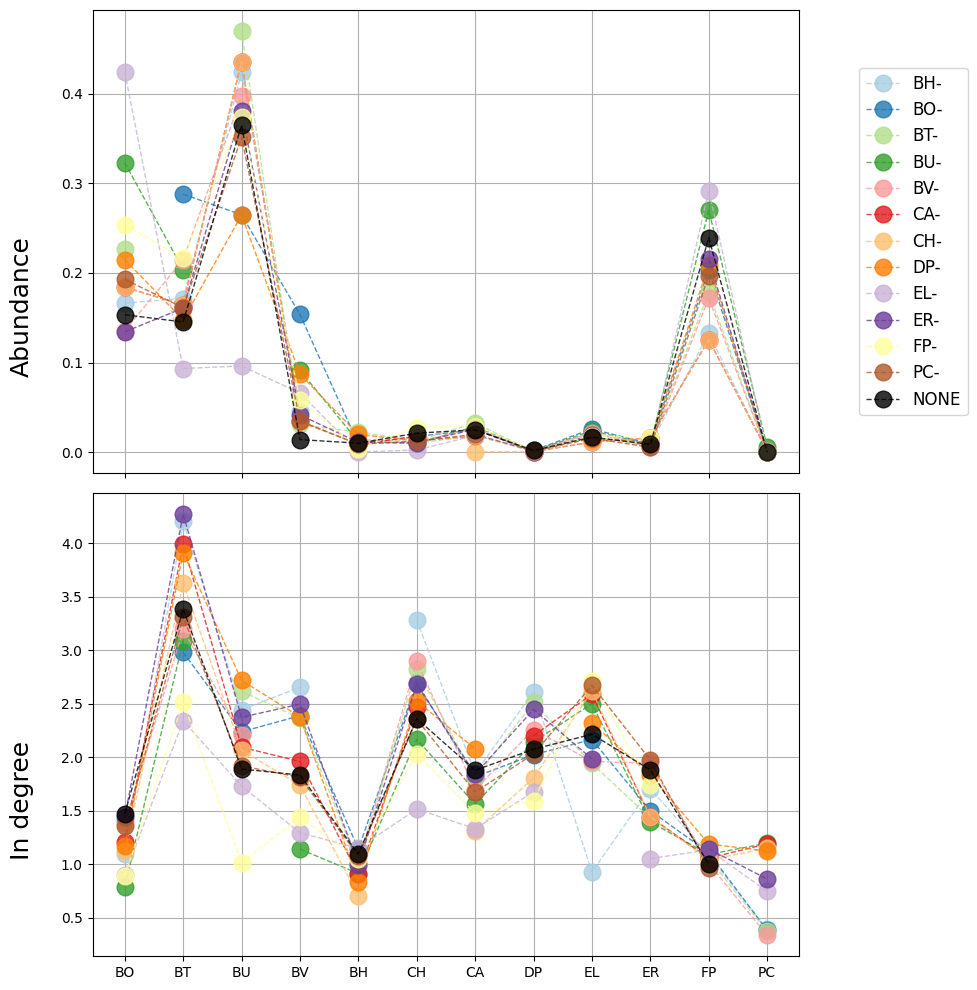

In [52]:
fig,ax = plt.subplots(2,figsize=(25,10))

abundances_exp_none = abundances_exp.drop("NONE",axis=1)

abundances_exp_none.plot(ax=ax[0],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
abundances_exp["NONE"].plot(ax=ax[0],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
labels = ax[0].set_xticklabels("",rotation=90)
title1 = ax[0].set_title("Abundance",x=-.1,y=0.2,fontsize=18,rotation=90)
ax[0].legend(loc='center right', bbox_to_anchor=(1.25, 0.5),fontsize=12)
ax[0].set_xlabel("")

centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(ax=ax[1],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
centrality_sorted.T["NONE"].plot(ax=ax[1],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
names = centrality_sorted.columns.values
x = [name.split("_")[0][0].upper()+name.split("_")[1][0].upper() for name in names]

ax[1].set_xticks(np.arange(len(x)))
labels = ax[1].set_xticklabels(x)
title2 = ax[1].set_title("In degree",x=-.1,y=0.2,fontsize=18,rotation=90)
plt.tight_layout()
fig.savefig("figures/degree_comm_in.png")

### Clustermap out degree

In [86]:
centrality_metrics_comm= {}

for comm in results.community.unique():
    results_comm = results[results.community==comm].copy()
    
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

In [87]:
centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()

names = centrality.columns.values
x = [name.split("_")[0][0].upper()+name.split("_")[1][0].upper() for name in names]
centrality.columns = x
centrality =centrality.sort_index()

In [88]:
centrality.columns.name="Member"
centrality.index.name="Community"
centrality

Member,BO,BT,BU,BV,BH,CH,CA,DP,EL,ER,FP,PC
Community,,,,,,,,,,,,
BH-,3.046917,1.445500,3.514333,1.872833,NaN,1.633833,1.269833,0.107,3.6865,0.773500,3.942000,0.95750
BO-,NaN,2.215500,2.006500,2.453500,1.341000,1.786000,1.552333,0.322,3.4430,0.921000,3.632833,0.76800
BT-,3.111667,NaN,2.854000,0.897417,1.369333,1.763000,1.650000,0.000,2.6215,0.900000,3.553333,0.59800
BU-,3.478726,1.266500,NaN,1.846250,1.387500,1.798833,1.609000,0.106,0.7870,0.970833,3.382583,1.35900
BV-,2.813533,1.547000,3.029500,NaN,1.241500,1.645500,1.614500,0.000,2.4975,0.750000,4.128500,0.63250
CA-,4.508583,1.349500,3.583250,1.649667,1.350500,2.054667,NaN,0.000,0.7105,0.947367,3.470500,1.48400
CH-,3.625967,1.292500,3.626167,1.900000,1.386500,NaN,0.462333,0.000,0.4245,1.281900,3.088000,1.54650
DP-,4.146967,1.238000,2.879500,2.405500,1.358000,1.681333,0.900167,NaN,2.5145,0.778000,3.743167,0.43825
EL-,3.440500,0.469167,0.476333,2.345833,0.166000,1.265833,1.786500,0.000,NaN,0.978167,3.147917,0.79925


In [89]:
import seaborn as sns

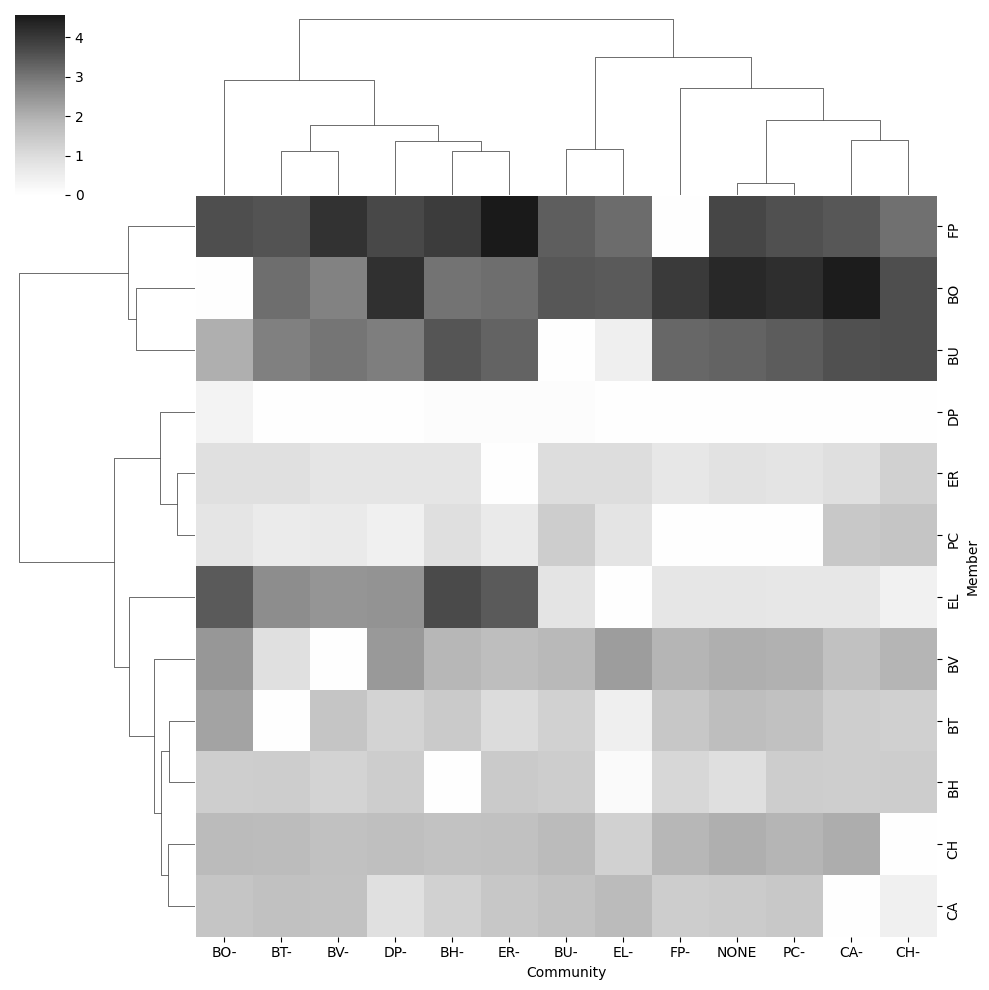

In [91]:
g = sns.clustermap(centrality.fillna(0).T,cmap="RdGy",center=0,method="ward")
plt.savefig("figures/clustermap_degree_comm2mem_out.png")

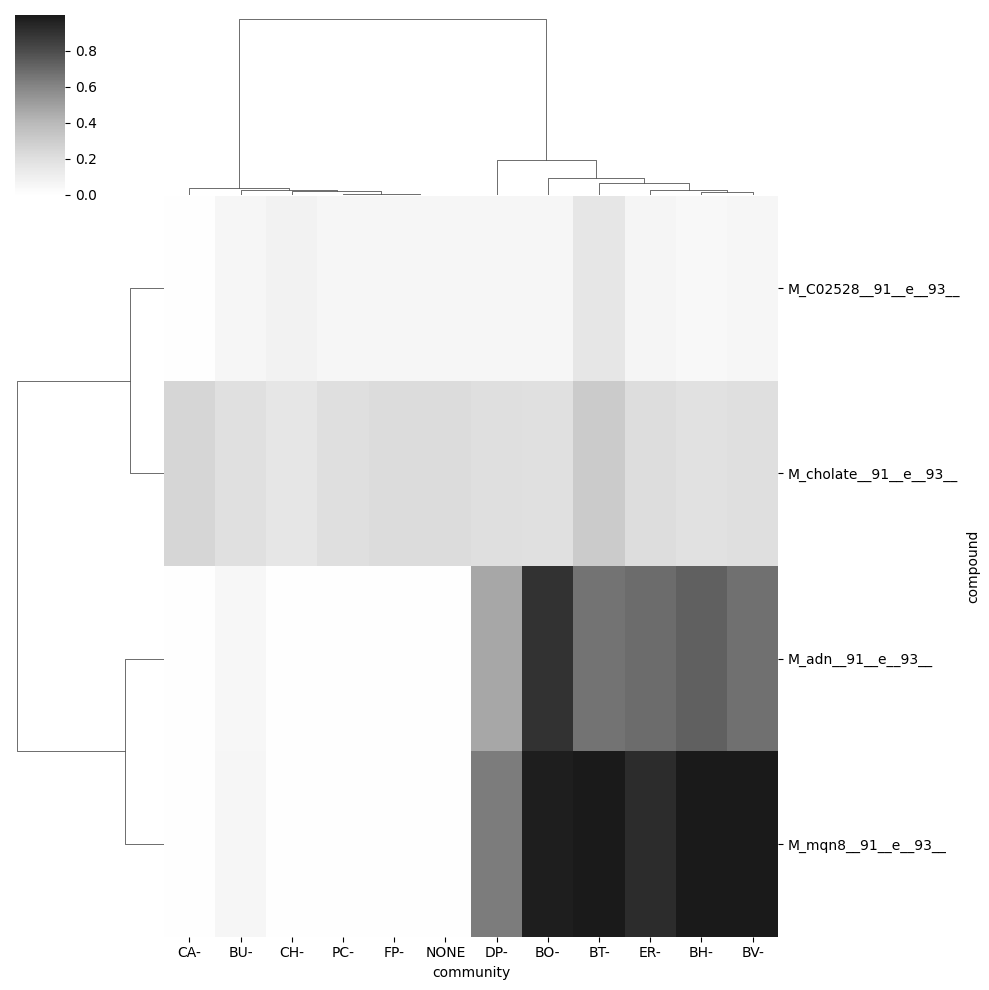

In [69]:
results_env = results[(results.donor!="environment") & (results.receiver!="environment")]
results_EG = results_env[(results_env.donor=="Eggerthella_lenta_DSM_2243")]

results_EG_grouped = results_EG[["community","compound","frequency"]].groupby(["community","compound"]).mean()["frequency"].unstack()

results_EG_grouped = results_EG_grouped.loc[:,results_EG_grouped.sum()>0.7].T.fillna(0)

sns.clustermap(results_EG_grouped,cmap="RdGy",center=0,method="ward")
plt.savefig("figures/clustermap_degree_EL_comm2met_out.png")

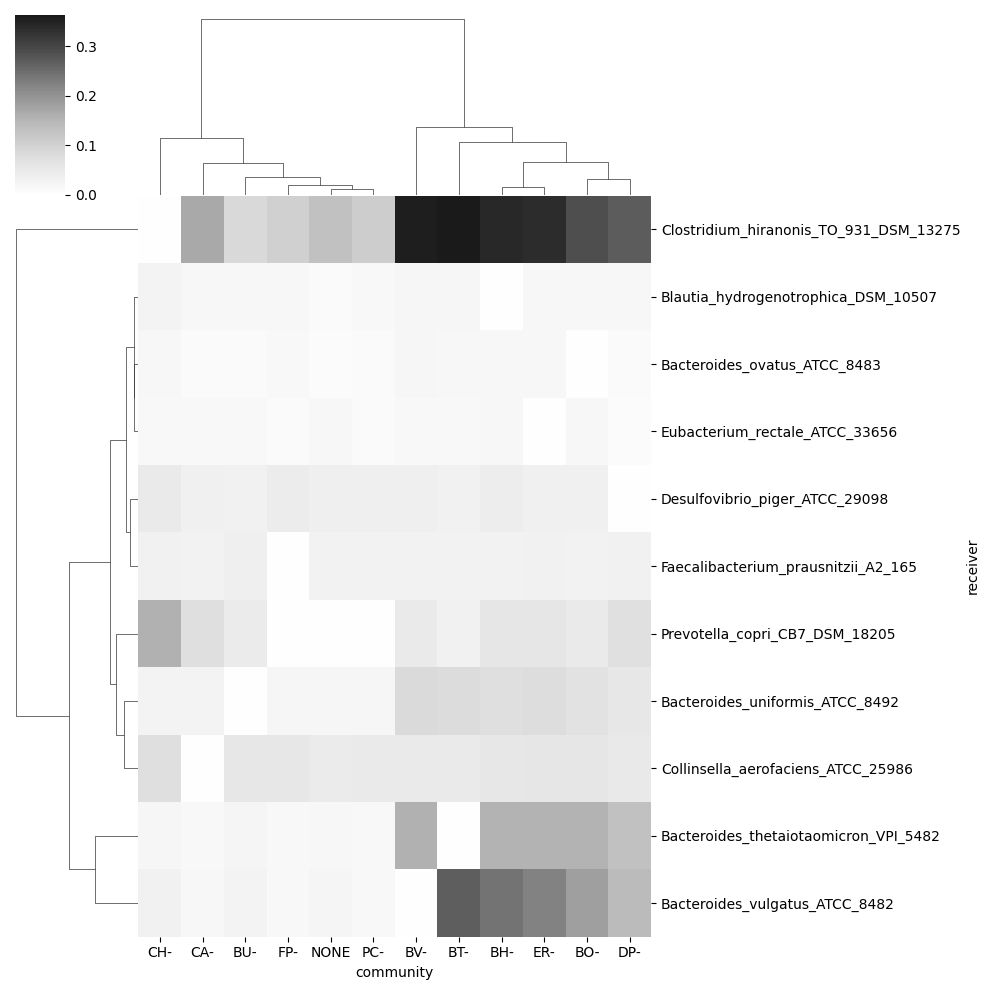

In [72]:
results_env = results[(results.donor!="environment") & (results.receiver!="environment")]
results_EG = results_env[(results_env.donor=="Eggerthella_lenta_DSM_2243")]

results_EG_grouped = results_EG[["community","receiver","frequency"]].groupby(["community","receiver"]).mean()["frequency"].unstack()

results_EG_grouped = results_EG_grouped.loc[:,results_EG_grouped.sum()>0.0].T.fillna(0)

sns.clustermap(results_EG_grouped,cmap="RdGy",center=0,method="ward")
plt.savefig("figures/clustermap_degree_EL_comm2mem_out.png")